# 02. Entrenamiento y evaluación

Este notebook documenta el pipeline que entrena y evalúa cada configuración del diseño experimental. El código vive en `src/router` y se organiza en módulos con una responsabilidad cada uno.

| Módulo | Responsabilidad |
|---|---|
| `config.py` | Dataclass `ExperimentConfig` con todos los hiperparámetros de una corrida y construcción del adapter PEFT de cada método |
| `prompts.py` | System prompt común a baselines y modelos ajustados |
| `datos.py` | Carga de splits, tokenización y collate con padding a la izquierda |
| `experimento.py` | Entrenamiento, evaluación y medición de VRAM, tiempo, energía y latencia |
| `metricas.py` | Macro-F1 por campo, JSON válido, exact match y acierto por slot |
| `grilla.py` | Bloques del diseño experimental con una semilla por réplica |

Los scripts `scripts/cola.py` y `scripts/correr.py` ejecutan las corridas en paralelo, una por GPU y cada una en un proceso nuevo, para que la medición de VRAM y tiempo de una corrida no se contamine con otra.

In [1]:
import sys, json, dataclasses
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from router import config, datos, esquema, prompts, grilla, analisis, graficos

graficos.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)

## Configuración de una corrida

Cada corrida se describe con una instancia de `ExperimentConfig`. El batch efectivo es 16 en todas las corridas y el entrenamiento dura dos épocas con schedule coseno y warmup de 5%. Los adapters se aplican a las siete proyecciones lineales de cada bloque del transformer (`q_proj`, `k_proj`, `v_proj`, `o_proj`, `gate_proj`, `up_proj` y `down_proj`).

In [2]:
# Configuración guardada de una corrida medida en A100.
corrida = json.load(open("../results/runs/lora_r8_lr0.0001_s1.json", encoding="utf-8"))
cfg = config.ExperimentConfig.desde_dict(corrida["config"])
pd.Series(dataclasses.asdict(cfg)).to_frame("valor")

,valor
run_id,lora_r8_lr0.0001_s1
bloque,lora
metodo,lora
seed,1234
replica,1
lr,0.0001
r,8
alpha_ratio,2.0
sparse_rate,None
theta_d_length,None


La función `construir_peft_config` traduce la configuración al objeto de PEFT de cada método. La capacidad del adapter se controla con un parámetro distinto en cada caso. En LoRA y MiCA es el rango `r`, en FRoD es `sparse_rate`, la fracción de entradas libres de la matriz de rotación dispersa, en Uni-LoRA es `theta_d_length`, el largo del único vector entrenable compartido por todas las capas, y en SHiRA es `r`, que fija un número de pesos entrenables igual al de un LoRA de rango `r`.

In [3]:
for metodo, kw in [("lora", {"r": 8}), ("mica", {"r": 8}), ("frod", {"sparse_rate": 0.01}), ("unilora", {"theta_d_length": 2**15}), ("shira", {"r": 8})]:
    c = config.ExperimentConfig(run_id="ejemplo", bloque="ejemplo", metodo=metodo, **kw)
    print(metodo.ljust(8), type(config.construir_peft_config(c)).__name__, kw)

W1021 15:46:00.932000 21324 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


lora     LoraConfig {'r': 8}
mica     LoraConfig {'r': 8}
frod     FrodConfig {'sparse_rate': 0.01}
unilora  UniLoraConfig {'theta_d_length': 32768}
shira    ShiraConfig {'r': 8}


## Prompt y formato de salida

Todos los modelos reciben el mismo system prompt, con las definiciones de intención, las reglas de agente, prioridad y aprobación, y el formato de los slots. El razonamiento de Granite 4.2 se desactiva con `enable_thinking=False`, por lo que el modelo responde directamente con el JSON. Durante el entrenamiento la pérdida se calcula solo sobre los tokens del JSON objetivo y el token de fin.

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(config.MODELO_BASE)
train = datos.cargar_split("train")
ejemplo = train[0]
texto_prompt = datos.texto_prompt(tok, ejemplo["texto"])
n_prompt = len(tok(texto_prompt, add_special_tokens=False)["input_ids"])
n_objetivo = len(tok(esquema.a_texto(ejemplo["salida"]), add_special_tokens=False)["input_ids"])
print(f"tokens del prompt {n_prompt}, tokens del JSON objetivo {n_objetivo}")
print("mensaje", ejemplo["texto"])
print("objetivo", esquema.a_texto(ejemplo["salida"]))

tokens del prompt 749, tokens del JSON objetivo 73
mensaje Lamentablemente debemos cancelar el team building de Lunahuaná del 14 de noviembre por recorte presupuestal. Dado el aviso anticipado, solicitamos que se nos exonere de la penalidad.
objetivo {"intencion": "cancelar", "agente": "logistica", "prioridad": "P3", "requiere_aprobacion_humana": true, "slots": {"destino": "Lunahuaná", "fecha": "14 de noviembre", "n_personas": null, "monto": null}}


## Detalles de implementación del entrenamiento

El prompt ocupa unos 700 tokens y el JSON objetivo menos de 100. Para no materializar logits de tamaño longitud por vocabulario sobre todo el prompt, el collate aplica padding a la izquierda y `perdida_cola` proyecta al vocabulario solo las últimas posiciones de cada batch, donde están todos los tokens con pérdida. Las `position_ids` se calculan a partir de la máscara de atención para que el padding no desplace las posiciones de RoPE. La equivalencia con la pérdida estándar de Hugging Face se verificó numéricamente (0.220874 contra 0.220874 en un batch de cuatro ejemplos).

Las corridas medidas se ejecutaron en dos GPUs NVIDIA A100 SXM4 de 80 GB, una corrida por GPU, sin gradient checkpointing, con micro-batch 4 y acumulación de gradientes 4. Tras el entrenamiento el adapter se fusiona con los pesos base (`merge_and_unload`) y la evaluación se hace sobre el modelo fusionado, que es la forma de despliegue. La latencia sin fusionar se mide aparte en cuatro solicitudes.

## Corrida de demostración

La celda siguiente entrena y evalúa una configuración completa con el mismo código de las corridas del diseño experimental. En este notebook se ejecutó en una GPU NVIDIA RTX 5070 Ti de 16 GB con gradient checkpointing, por lo que sus tiempos no son comparables con los de las corridas medidas en A100. Las métricas de calidad sí son comparables.

In [5]:
import os
from pathlib import Path
EJECUTAR_DEMO = True
os.environ["ROUTER_RESULTADOS"] = str(Path("../results/demo").resolve())
from router import experimento
experimento.DIR_RESULTADOS = Path(os.environ["ROUTER_RESULTADOS"])
experimento.DIR_RUNS = experimento.DIR_RESULTADOS / "runs"
experimento.DIR_PREDS = experimento.DIR_RESULTADOS / "preds"

demo_cfg = config.ExperimentConfig(run_id="demo_lora_r8_lr0.0001", bloque="demo", metodo="lora", r=8, lr=1e-4,
                                   micro_batch=8, grad_accum=2, gradient_checkpointing=True)
if EJECUTAR_DEMO:
    res = experimento.correr(demo_cfg)
    resumen = {k: round(res["test"][k], 4) for k in ("score", "f1_intencion", "f1_agente", "f1_prioridad", "json_valido", "exact_match", "acc_slots")}
    print(res["entorno"]["gpu"], f"params {res['params_entrenables']:,}", f"train {res['entrenamiento']['train_segundos']/60:.1f} min")
    display(pd.Series(resumen).to_frame("test"))

NVIDIA GeForce RTX 5070 Ti params 15,564,800 train 9.8 min


,test
score,0.9441
f1_intencion,0.9439
f1_agente,0.9682
f1_prioridad,0.9203
json_valido,1.0000
exact_match,0.6939
acc_slots,0.9643


## Reproducción del diseño completo

Los bloques del diseño se ejecutan con la cola. Cada corrida guarda un JSON en `results/runs` con la configuración, las métricas de validación y test, la VRAM pico, los tiempos, la energía y la latencia, y las predicciones crudas en `results/preds`. La cola omite las corridas ya terminadas, por lo que puede reanudarse tras una interrupción.

```bash
uv sync
export ROUTER_GRADIENT_CHECKPOINTING=0 ROUTER_MICRO_BATCH=4 ROUTER_GRAD_ACCUM=4
bash scripts/correr_bloques.sh 2 base piloto barrido_lr
bash scripts/lanzar_principal.sh 2
uv run python scripts/cola.py --bloque validacion --r <r*> --lr <lr*> --gpus 2
```

## Análisis de errores del mejor modelo

Se toma la configuración con mayor score medio en validación entre las réplicas del diseño principal y se analizan sus predicciones de test de la primera réplica.

In [6]:
df = analisis.cargar_corridas(Path("../results/runs"))
principal = df[df.bloque.isin(["lora", "metodos", "validacion"])]
por_config = principal.groupby(["metodo", "capacidad", "lr"]).agg(val=("val_score", "mean"), test=("test_score", "mean"), n=("val_score", "size")).reset_index()
mejor = por_config.sort_values("val", ascending=False).iloc[0]
fila = principal[(principal.metodo == mejor.metodo) & (principal.capacidad == mejor.capacidad) & (principal.lr == mejor.lr) & (principal.replica == 1)].iloc[0]
print(f"mejor configuración en validación: {fila.nombre} {fila.capacidad} lr {fila.lr:g} (score val medio {mejor.val:.3f}, test medio {mejor.test:.3f})")

test = {f["id"]: f for f in datos.cargar_split("test")}
preds = [json.loads(l) for l in open(f"../results/preds/{fila.run_id}_test.jsonl", encoding="utf-8")]
filas = []
for p in preds:
    ref = test[p["id"]]["salida"]
    pr = p["parseada"] if esquema.salida_valida(p["parseada"]) else {}
    filas.append({"id": p["id"], "texto": test[p["id"]]["texto"], "origen": test[p["id"]]["origen"],
                  **{f"real_{c}": ref[c] for c in ("intencion", "agente", "prioridad", "requiere_aprobacion_humana")},
                  **{f"pred_{c}": pr.get(c) for c in ("intencion", "agente", "prioridad", "requiere_aprobacion_humana")}})
err = pd.DataFrame(filas)
for c in ("intencion", "agente", "prioridad", "requiere_aprobacion_humana"):
    err[f"ok_{c}"] = err[f"real_{c}"] == err[f"pred_{c}"]
err.groupby("origen")[[f"ok_{c}" for c in ("intencion", "agente", "prioridad", "requiere_aprobacion_humana")]].mean().round(3)

mejor configuración en validación: SHiRA r=32 lr 0.0001 (score val medio 0.956, test medio 0.958)


,ok_intencion,ok_agente,ok_prioridad,ok_requiere_aprobacion_humana
origen,,,,
gold,0.948,0.938,0.927,0.958
lote,0.980,0.990,0.960,0.980


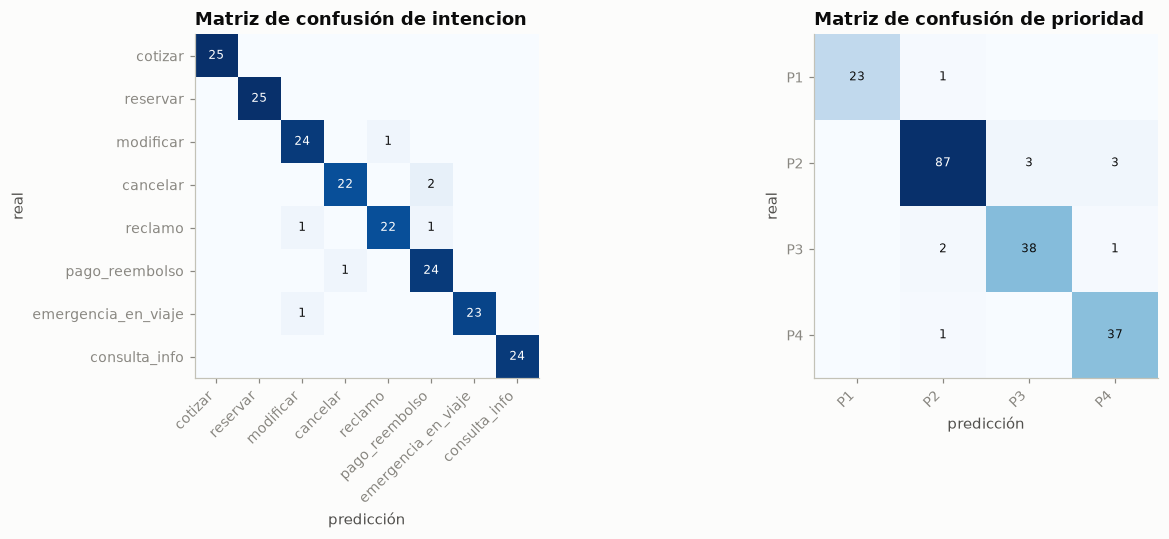

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, campo, clases in ((ejes[0], "intencion", esquema.INTENCIONES), (ejes[1], "prioridad", esquema.PRIORIDADES)):
    m = confusion_matrix(err[f"real_{campo}"], err[f"pred_{campo}"].fillna("invalido"), labels=list(clases))
    ax.imshow(m, cmap="Blues")
    ax.set_xticks(range(len(clases)), clases, rotation=45, ha="right")
    ax.set_yticks(range(len(clases)), clases)
    for i in range(len(clases)):
        for j in range(len(clases)):
            if m[i, j]:
                ax.text(j, i, m[i, j], ha="center", va="center", fontsize=8, color="white" if m[i, j] > m.max() / 2 else graficos.TINTA)
    ax.set_xlabel("predicción")
    ax.set_ylabel("real")
    ax.set_title(f"Matriz de confusión de {campo}", loc="left")
    ax.grid(False)
fig.tight_layout()

In [8]:
errores = err[~(err.ok_intencion & err.ok_agente & err.ok_prioridad)]
print(f"{len(errores)} de {len(err)} mensajes de test tienen al menos un error en intención, agente o prioridad")
errores[["texto", "origen", "real_intencion", "pred_intencion", "real_prioridad", "pred_prioridad"]].head(12)

19 de 196 mensajes de test tienen al menos un error en intención, agente o prioridad


,texto,origen,real_intencion,pred_intencion,real_prioridad,pred_prioridad
2,"Señores, reclamo que no me hayan respondido en 3 días. Además necesito pasar nuestro viaje a Ayacucho para el 22 de noviembre, por motiv...",lote,modificar,reclamo,P3,P3
17,"me cobraron 2 veces los 320 soles del tour de Paracas y encima ya no lo quiero, cancélenlo y regresen ambos cobros",gold,cancelar,pago_reembolso,P2,P2
23,"el bus cama q nos vendieron era semicama y el aire no funcionaba, pésimo. y encima me cobraron 20 soles de cargo x servicio q nadie menc...",lote,reclamo,reclamo,P2,P4
31,"plis can u fix el nombre en mi ticket a Lima for next monday? es Kathy con h, no Katty 🙏",gold,modificar,modificar,P3,P2
33,"Buenas, necesitamos la factura del retiro corporativo a nombre de Inversiones Lurín SAC, RUC 20548796321. El servicio se pagó hace dos s...",gold,pago_reembolso,pago_reembolso,P4,P2
40,"Gracias por el 'hotel 4 estrellas' en Piura, seguro las estrellas se ven por los huecos del techo 👏. Tres noches sin agua caliente. Quie...",gold,reclamo,reclamo,P2,P4
48,"Ya estamos de viaje pero el tour de trekking que venía en el paquete lo cancelamos, mi esposa prefiere descansar en el hotel. ¿Nos devue...",gold,cancelar,pago_reembolso,P2,P2
55,Les escribe Patricia de RR.HH. de Grupo Sigma. Uno de nuestros gerentes que está en el viaje de incentivo en Cartagena tuvo un dolor fue...,gold,emergencia_en_viaje,emergencia_en_viaje,P1,P1
70,"Pagué 2500 por un hotel 'cuatro estrellas' en Máncora y era una pocilga. No quiero plata de vuelta, quiero que lo sepan y que no le pase...",gold,reclamo,pago_reembolso,P4,P4
73,"Se nos pasó el tren de regreso de Aguas Calientes, cámbiennos al siguiente por favor que estamos acá parados los 3",gold,emergencia_en_viaje,modificar,P1,P2


Sobre 196 mensajes de test, el modelo comete 7 errores de intención y 11 de prioridad. Los errores de intención se concentran en mensajes con varios pedidos, donde la regla de precedencia define la etiqueta. En dos casos el cliente cancela y además pide la devolución del dinero, y el modelo predice `pago_reembolso` aunque `cancelar` tiene mayor precedencia. Los errores de prioridad se concentran en la clase P2, que agrupa tres condiciones distintas (plazo cercano, dinero en disputa y pedido de atención humana o legal). Seis de los 11 errores son mensajes P2 predichos como P3 o P4. La precisión en el lote gold es entre 2 y 5 puntos menor que en los lotes regulares, lo que es consistente con su mayor dificultad.